https://tradingeconomics.com
https://www.kaggle.com/datasets/madhurpant/world-economic-data
https://data.worldbank.org/indicator/SP.DYN.LE00.IN

# Preparing

In [1]:
#!pip install "kagglehub[pandas-datasets]"

In [2]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

In [3]:
kagglehub.dataset_download("madhurpant/world-economic-data")

'/Users/oscarrobertson/.cache/kagglehub/datasets/madhurpant/world-economic-data/versions/1'

In [4]:
import os

In [5]:
os.listdir('/Users/oscarrobertson/.cache/kagglehub/datasets/madhurpant/world-economic-data/versions/1')

['richest_countries.csv',
 'cost_of_living.csv',
 'tourism.csv',
 'corruption.csv',
 'unemployment.csv']

In [6]:
import pandas as pd

In [7]:
import plotly.express as px

# Creating, cleaning and manipulating dataframes

## Creating Dataframes

In [67]:
df_unemployment = pd.read_csv('/Users/oscarrobertson/.cache/kagglehub/datasets/madhurpant/world-economic-data/versions/1/unemployment.csv')

In [9]:
df_corruption = pd.read_csv('/Users/oscarrobertson/.cache/kagglehub/datasets/madhurpant/world-economic-data/versions/1/corruption.csv')

In [10]:
df_tourism = pd.read_csv('/Users/oscarrobertson/.cache/kagglehub/datasets/madhurpant/world-economic-data/versions/1/tourism.csv')

In [11]:
df_cost_of_living = pd.read_csv('/Users/oscarrobertson/.cache/kagglehub/datasets/madhurpant/world-economic-data/versions/1/cost_of_living.csv')

In [12]:
df_richest_countries = pd.read_csv('/Users/oscarrobertson/.cache/kagglehub/datasets/madhurpant/world-economic-data/versions/1/richest_countries.csv')

In [13]:
df_richest_countries.head()

,country,gdp_per_capita
0,Luxembourg,134754
1,Singapore,116486
2,Ireland,106456
3,Qatar,93521
4,Bermuda,85192


In [14]:
df_richest_countries.shape

(50, 2)

In [15]:
df_cost_of_living.head()

,country,cost_index,monthly_income,purchasing_power_index
0,Bermuda,157.6,9712,105.0
1,Switzerland,142.4,7530,90.1
2,Cayman Islands,137.9,5281,65.2
3,Israel,130.2,4130,54.1
4,Iceland,128.0,5368,71.5


In [16]:
df_cost_of_living.shape

(107, 4)

In [17]:
df_tourism.head()

,country,tourists_in_millions,receipts_in_billions,receipts_per_tourist,percentage_of_gdp
0,France,117.1,35.96,307,1.2
1,Mexico,51.1,11.45,224,0.9
2,United States,45.0,84.21,1870,0.4
3,Italy,38.4,20.46,533,1.0
4,Hungary,31.6,4.22,133,2.3


In [18]:
df_tourism.shape

(41, 5)

In [19]:
df_corruption.head()

,country,annual_income,corruption_index
0,Denmark,68110,12
1,Finland,53660,12
2,New Zealand,45340,12
3,Norway,84090,15
4,Singapore,64010,15


In [20]:
df_corruption.shape

(110, 3)

In [21]:
df_unemployment.head()

,country,unemployment_rate
0,Marshall Islands,36.0
1,South Africa,33.6
2,Kiribati,30.6
3,Kosovo,30.5
4,American Samoa,29.8


In [22]:
df_unemployment.shape

(64, 2)

In [23]:
world_economic_data_dfs = [df_richest_countries, df_cost_of_living, df_tourism, df_corruption, df_unemployment]

In [24]:
for df in world_economic_data_dfs:
    df.set_index('country', inplace=True)

In [25]:
df2 = pd.merge(df_richest_countries, df_cost_of_living, on='country', how='outer')

In [26]:
df3 = df2.merge(df_tourism, on='country', how='outer')

In [27]:
df4 = df3.merge(df_corruption, on='country', how='outer')

In [28]:
df = df4.merge(df_unemployment, on='country', how='outer')

In [29]:
df.rename(columns={'percentage_of_gdp':'tourism_percentage_gdp'}, inplace=True)

In [30]:
df

,gdp_per_capita,cost_index,monthly_income,purchasing_power_index,tourists_in_millions,receipts_in_billions,receipts_per_tourist,tourism_percentage_gdp,annual_income,corruption_index,unemployment_rate
country,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,500.0,84.0,NaN
Albania,NaN,52.0,509.0,16.7,2.7,1.24,468.0,6.8,NaN,NaN,NaN
Algeria,NaN,29.9,305.0,17.4,NaN,NaN,NaN,NaN,3660.0,67.0,NaN
American Samoa,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29.8
Angola,NaN,23.0,148.0,10.9,NaN,NaN,NaN,NaN,1770.0,71.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...
Vietnam,NaN,34.4,297.0,14.7,3.8,3.23,842.0,0.9,3560.0,61.0,2.2
Virgin Islands,NaN,NaN,NaN,NaN,8.6,0.69,80.0,16.3,NaN,NaN,NaN
Yemen,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,670.0,84.0,NaN


In [31]:
df.loc['Nigeria']

gdp_per_capita               NaN
cost_index                  41.8
monthly_income             175.0
purchasing_power_index       7.1
tourists_in_millions         NaN
receipts_in_billions         NaN
receipts_per_tourist         NaN
tourism_percentage_gdp       NaN
annual_income             2100.0
corruption_index            76.0
unemployment_rate            9.8
Name: Nigeria, dtype: float64

In [32]:
df.loc['United Kingdom']

gdp_per_capita            49675.0
cost_index                  107.9
monthly_income             3782.0
purchasing_power_index       59.7
tourists_in_millions          NaN
receipts_in_billions          NaN
receipts_per_tourist          NaN
tourism_percentage_gdp        NaN
annual_income             45380.0
corruption_index             22.0
unemployment_rate             4.5
Name: United Kingdom, dtype: float64

In [33]:
df_dropna = df.dropna()

In [34]:
df_dropna

,gdp_per_capita,cost_index,monthly_income,purchasing_power_index,tourists_in_millions,receipts_in_billions,receipts_per_tourist,tourism_percentage_gdp,annual_income,corruption_index,unemployment_rate
country,,,,,,,,,,,
Australia,55807.0,118.0,4730.0,68.3,1.8,26.23,14351.0,1.7,56760.0,27.0,5.1
France,50729.0,96.2,3657.0,64.7,117.1,35.96,307.0,1.2,43880.0,29.0,8.1
Germany,57928.0,92.3,4253.0,78.5,12.4,58.37,4689.0,1.4,51040.0,20.0,3.5
Greece,31295.0,74.7,1678.0,38.3,7.4,6.19,836.0,2.9,20140.0,51.0,14.8
Hong Kong,65973.0,77.9,4538.0,99.2,3.6,32.70,9161.0,8.9,54450.0,24.0,5.3
Italy,45936.0,86.2,2976.0,58.8,38.4,20.46,533.0,1.0,35710.0,44.0,9.8
Japan,42940.0,101.9,3552.0,59.4,4.1,11.40,2769.0,0.2,42620.0,27.0,2.8
Luxembourg,134754.0,113.1,6759.0,101.8,0.5,4.45,8484.0,5.1,81110.0,19.0,5.2
Netherlands,63767.0,99.0,4698.0,80.8,7.3,10.93,1504.0,1.1,56370.0,18.0,4.0


## GDP per capita sample graph

In [35]:
df_gdp_per_capita = df['gdp_per_capita'].dropna()

In [36]:
df_gdp_sample = df_gdp_per_capita.sample(10, random_state=14)

In [37]:
df_gdp_sample

country
Turkey          30472.0
Israel          43722.0
France          50729.0
New Zealand     46420.0
Romania         35414.0
Singapore      116486.0
Iceland         57646.0
Austria         58427.0
Bahamas         34108.0
Brunei          66620.0
Name: gdp_per_capita, dtype: float64

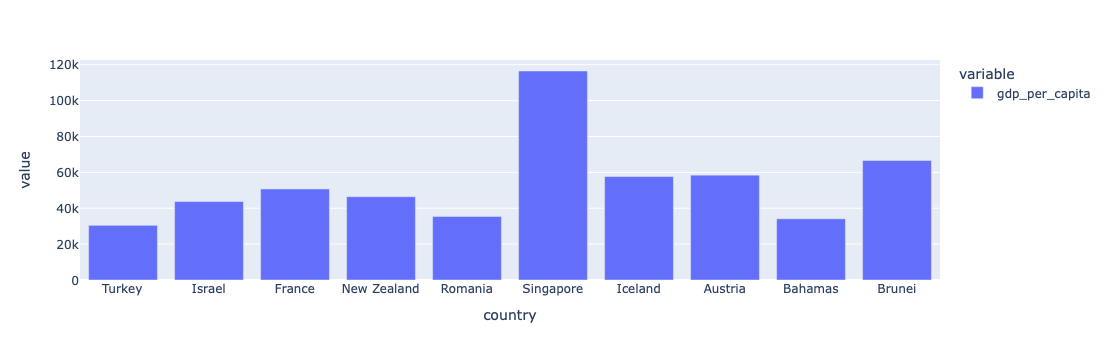

In [38]:
px.bar(df_gdp_sample)

## Cutting draft to key columns

In [39]:
df = df[['annual_income', 'corruption_index', 'unemployment_rate']].dropna().sort_values(by='annual_income')

In [68]:
df

,annual_income,corruption_index,unemployment_rate,life_expectancy
country,,,,
Burundi,240.0,81.0,1.8,63.8
Niger,590.0,69.0,0.8,61.4
Chad,650.0,80.0,1.9,55.2
Pakistan,1500.0,72.0,4.4,67.8
Cambodia,1550.0,77.0,0.6,70.8
Nigeria,2100.0,76.0,9.8,54.6
India,2170.0,60.0,6.0,72.2
Bangladesh,2620.0,74.0,5.2,74.9
Djibouti,3300.0,70.0,28.4,66.2


In [41]:
df_sample = df.sample(10, random_state=2)

In [42]:
df_sample.sort_values(by='annual_income')

,annual_income,corruption_index,unemployment_rate
country,,,
Burundi,240.0,81.0,1.8
Djibouti,3300.0,70.0,28.4
Eswatini,3680.0,68.0,25.8
Malaysia,10930.0,52.0,4.6
Greece,20140.0,51.0,14.8
Canada,48310.0,26.0,7.5
Netherlands,56370.0,18.0,4.0
Denmark,68110.0,12.0,4.8
Ireland,74520.0,26.0,6.6


## Life expectancies

In [43]:
df_life_expectances = pd.read_csv('API_SP.DYN.LE00.IN_DS2_en_csv_v2_460061.csv', skiprows=4)

In [44]:
df_life_expectances

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,64.049000,64.215000,64.602000,64.944000,65.303000,65.615000,...,75.620000,75.880000,76.019000,75.406000,73.655000,76.226000,76.353000,76.500000,NaN,NaN
1,Africa Eastern and Southern,AFE,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,44.169658,44.468838,44.877890,45.160583,45.535695,45.770723,...,62.591275,63.330691,63.857261,63.766484,62.979999,64.487152,65.146228,65.349930,NaN,NaN
2,Afghanistan,AFG,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,32.799000,33.291000,33.757000,34.201000,34.673000,35.124000,...,62.406000,62.443000,62.941000,61.454000,60.417000,65.617000,66.035000,66.289000,NaN,NaN
3,Africa Western and Central,AFW,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,37.779636,38.058973,38.681792,38.936918,39.194375,39.478875,...,56.620764,57.030771,57.142827,57.357709,57.355015,57.978995,58.847483,59.041538,NaN,NaN
4,Angola,AGO,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,37.933000,36.902000,37.168000,37.419000,37.704000,37.968000,...,62.122000,62.622000,63.051000,63.116000,62.958000,64.246000,64.617000,64.805000,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
260,Kosovo,XKX,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,48.702000,49.883000,48.378000,50.098000,51.119000,52.003000,...,77.105000,77.117000,77.249000,74.212000,74.981000,77.623000,78.033000,78.222000,NaN,NaN
261,"Yemen, Rep.",YEM,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,33.462000,34.058000,33.669000,33.431000,34.907000,35.592000,...,67.120000,65.915000,66.567000,66.435000,66.019000,67.952000,69.295000,69.439000,NaN,NaN
262,South Africa,ZAF,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,52.575000,53.067000,53.566000,53.895000,54.215000,54.427000,...,65.422000,65.726000,66.071000,65.150000,62.010000,65.454000,66.139000,66.312000,NaN,NaN
263,Zambia,ZMB,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,50.648000,51.041000,51.331000,51.605000,51.170000,52.079000,...,61.564000,62.138000,62.914000,63.361000,62.363000,65.279000,66.349000,66.528000,NaN,NaN


In [45]:
df_life_expectances.rename(columns={'Country Name':'country'}, inplace=True)

In [46]:
df_life_expectances.set_index('country', inplace=True)

In [47]:
df_life_expectances.columns

Index(['Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961',
       '1962', '1963', '1964', '1965', '1966', '1967', '1968', '1969', '1970',
       '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979',
       '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988',
       '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997',
       '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006',
       '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015',
       '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024',
       '2025', 'Unnamed: 70'],
      dtype='object')

In [48]:
df_life_expectances2 = df_life_expectances[['1960', '1970', '1980', '1990', '2000', '2010', '2020']]

In [49]:
df_life_expectances2

,1960,1970,1980,1990,2000,2010,2020
country,,,,,,,
Aruba,64.049000,67.440000,70.771000,72.546000,72.939000,74.297000,75.406000
Africa Eastern and Southern,44.169658,47.248006,49.816713,51.096326,52.557342,58.827279,63.766484
Afghanistan,32.799000,37.460000,39.258000,45.118000,55.005000,60.702000,61.454000
Africa Western and Central,37.779636,41.273639,46.691792,48.451159,50.292605,54.600647,57.357709
Angola,37.933000,39.688000,42.242000,41.854000,46.501000,57.242000,63.116000
...,...,...,...,...,...,...,...
Kosovo,48.702000,54.002000,60.297000,66.508000,71.321000,74.609000,74.212000
"Yemen, Rep.",33.462000,40.573000,50.608000,58.528000,62.761000,67.223000,66.435000
South Africa,52.575000,55.681000,59.961000,62.942000,58.368000,58.886000,65.150000


In [50]:
df_sample.index

Index(['Canada', 'Luxembourg', 'Greece', 'Djibouti', 'Eswatini', 'Burundi',
       'Denmark', 'Ireland', 'Netherlands', 'Malaysia'],
      dtype='object', name='country')

In [51]:
df_life_sample = df_life_expectances2.loc[df_sample.index]

In [52]:
df_life_sample.columns.name = 'years'

In [53]:
df_life_sample

years,1960,1970,1980,1990,2000,2010,2020
country,,,,,,,
Canada,71.133171,72.700488,75.102195,77.436585,79.166829,81.322195,81.530000
Luxembourg,68.800561,69.208098,72.258171,74.775488,77.873171,80.631707,82.143902
Greece,70.434317,72.680780,74.506561,76.939024,77.887805,80.387805,81.287805
Djibouti,43.421000,47.536000,52.046000,55.469000,56.734000,60.743000,64.200000
Eswatini,46.389000,51.208000,58.227000,61.167000,47.627000,48.331000,59.862000
Burundi,43.262000,43.225000,45.731000,45.184000,47.617000,57.088000,62.569000
Denmark,72.176585,73.343415,74.101707,74.805366,76.592683,79.100000,81.602439
Ireland,70.194268,70.901561,72.595415,74.846073,76.536585,80.743902,82.456098
Netherlands,73.392683,73.585610,75.743171,76.878049,77.987805,80.702439,81.358537


In [54]:
df_life_sampleT = df_life_sample.T

In [55]:
df_life_sampleT

country,Canada,Luxembourg,Greece,Djibouti,Eswatini,Burundi,Denmark,Ireland,Netherlands,Malaysia
years,,,,,,,,,,
1960,71.133171,68.800561,70.434317,43.421,46.389,43.262,72.176585,70.194268,73.392683,57.168
1970,72.700488,69.208098,72.680780,47.536,51.208,43.225,73.343415,70.901561,73.585610,63.298
1980,75.102195,72.258171,74.506561,52.046,58.227,45.731,74.101707,72.595415,75.743171,68.061
1990,77.436585,74.775488,76.939024,55.469,61.167,45.184,74.805366,74.846073,76.878049,70.952
2000,79.166829,77.873171,77.887805,56.734,47.627,47.617,76.592683,76.536585,77.987805,72.732
2010,81.322195,80.631707,80.387805,60.743,48.331,57.088,79.100000,80.743902,80.702439,75.376
2020,81.530000,82.143902,81.287805,64.200,59.862,62.569,81.602439,82.456098,81.358537,76.057


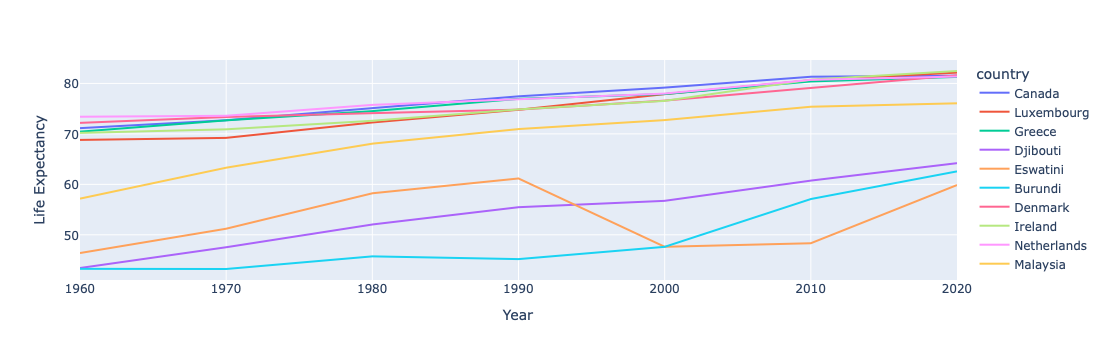

In [69]:
px.line(df_life_sampleT, labels={'value':'Life Expectancy', 'years':'Year'})

In [57]:
df_life_expectances['2024']

country
Aruba                          76.500000
Africa Eastern and Southern    65.349930
Afghanistan                    66.289000
Africa Western and Central     59.041538
Angola                         64.805000
                                 ...    
Kosovo                         78.222000
Yemen, Rep.                    69.439000
South Africa                   66.312000
Zambia                         66.528000
Zimbabwe                       63.064000
Name: 2024, Length: 265, dtype: float64

In [58]:
df = df.merge(df_life_expectances['2024'], on='country', how='inner')

In [61]:
df.rename(columns={'2024':'life_expectancy'}, inplace=True)

In [65]:
df = df.round(1)

In [66]:
df

,annual_income,corruption_index,unemployment_rate,life_expectancy
country,,,,
Burundi,240.0,81.0,1.8,63.8
Niger,590.0,69.0,0.8,61.4
Chad,650.0,80.0,1.9,55.2
Pakistan,1500.0,72.0,4.4,67.8
Cambodia,1550.0,77.0,0.6,70.8
Nigeria,2100.0,76.0,9.8,54.6
India,2170.0,60.0,6.0,72.2
Bangladesh,2620.0,74.0,5.2,74.9
Djibouti,3300.0,70.0,28.4,66.2


# Introduction

Economic development involves many improvements. This project aims to investigate the relationships between annual income, corruption index, unemployment rate and life expectancy across a sample of 10 countries. Using Python, the data will be analysed through statistical summaries, visualisations, and correlation coefficients to explore how elements of economic growth correlate with each other.

# Dataset

In [89]:
df = df.sample(10, random_state=37)
df

,annual_income,corruption_index,unemployment_rate,life_expectancy
country,,,,
Sri Lanka,3820.0,63.0,5.4,77.7
Niger,590.0,69.0,0.8,61.4
Indonesia,4140.0,62.0,4.4,71.3
Thailand,7260.0,65.0,1.4,76.6
Cambodia,1550.0,77.0,0.6,70.8
Italy,35710.0,44.0,9.8,84.0
Spain,29740.0,39.0,14.7,83.9
Burundi,240.0,81.0,1.8,63.8
Switzerland,90360.0,16.0,5.3,84.4


# Data Dictionary

In [158]:
data_dict = pd.DataFrame({'Meaning': ['Average annual income per person',
                                     'Measure of perceived corruption', 
                                     'Percentage of the labour force unemployed',
                                        'Average expected lifespan'],
                         'Unit': ['USD per person per year',
                                  'Index score (0-100)',
                                  '%', 'Years'],
                         'Data type': 'float'},
             index=['annual_income', 'corruption_index', 'unemployment_rate', 'life_expectancy'])

In [102]:
data_dict

,Meaning,Unit,Data type
annual_income,Average annual income per person,USD per person per year,float
corruption_index,Measure of perceived corruption,Index score (0-100),float
unemployment_rate,Percentage of the labour force unemployed,%,float
life_expectancy,Average expected lifespan,Years,float


# Independent Variables

## Annual Income

In [112]:
# meaning of annual income
data_dict.loc['annual_income', 'Meaning']

'Average annual income per person'

In [109]:
df['annual_income'].sort_values(ascending=False)

country
Switzerland    90360.0
Australia      56760.0
Italy          35710.0
Spain          29740.0
Thailand        7260.0
Indonesia       4140.0
Sri Lanka       3820.0
Cambodia        1550.0
Niger            590.0
Burundi          240.0
Name: annual_income, dtype: float64

In [165]:
df['annual_income'].describe().round(2)

count       10.0
mean     23017.0
std      30433.4
min        240.0
25%       2117.5
50%       5700.0
75%      34217.5
max      90360.0
Name: annual_income, dtype: float64

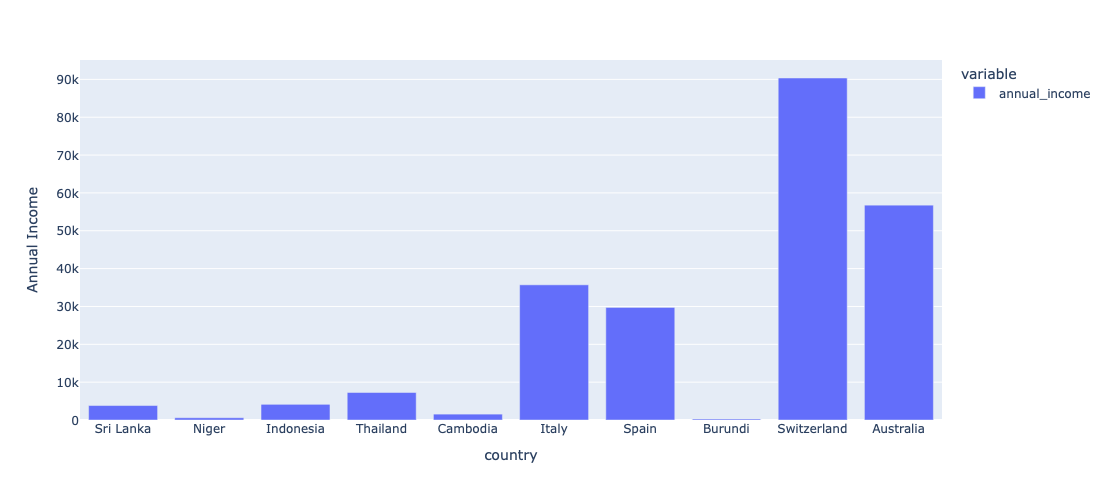

In [121]:
px.bar(df['annual_income'], labels={'value':'Annual Income'}, height=500)

Switzerland has the highest annual income of the sample, while Burundi has the lowest. The data shows a general trend of European countries and Australia having higher annual income, followed by Asian countries and lastly, African coutries. The difference between values is very large.

## Corruption Index

In [111]:
# meaning of corruption index
data_dict.loc['corruption_index', 'Meaning']

'Measure of perceived corruption'

In [113]:
df['corruption_index'].sort_values(ascending=False)

country
Burundi        81.0
Cambodia       77.0
Niger          69.0
Thailand       65.0
Sri Lanka      63.0
Indonesia      62.0
Italy          44.0
Spain          39.0
Australia      27.0
Switzerland    16.0
Name: corruption_index, dtype: float64

In [167]:
df['corruption_index'].describe().round(2)

count    10.00
mean     54.30
std      21.72
min      16.00
25%      40.25
50%      62.50
75%      68.00
max      81.00
Name: corruption_index, dtype: float64

Overall, the sample data portrays that corruption is less in Europe and Australia than in the rest of the world. With it being especially high in Burundi and Cambodia and low in Switzerland.

## Unemployment Rate

In [114]:
# meaning of unemployment rate
data_dict.loc['unemployment_rate', 'Meaning']

'Percentage of the labour force unemployed'

In [115]:
df['unemployment_rate'].sort_values(ascending=False)

country
Spain          14.7
Italy           9.8
Sri Lanka       5.4
Switzerland     5.3
Australia       5.1
Indonesia       4.4
Burundi         1.8
Thailand        1.4
Niger           0.8
Cambodia        0.6
Name: unemployment_rate, dtype: float64

In [168]:
df['unemployment_rate'].describe().round(2)

count    10.00
mean      4.93
std       4.45
min       0.60
25%       1.50
50%       4.75
75%       5.38
max      14.70
Name: unemployment_rate, dtype: float64

The unemployment rate of Spain and Italy are especially high, whilst Burundi, Thailand, Niger, and Cambodia are much lower; the remaining countries are inbetween.

## Life expectancy

In [122]:
# meaning of life expectancy
data_dict.loc['life_expectancy', 'Meaning']

'Average expected lifespan'

In [123]:
df['life_expectancy'].sort_values(ascending=False)

country
Switzerland    84.4
Italy          84.0
Spain          83.9
Australia      83.1
Sri Lanka      77.7
Thailand       76.6
Indonesia      71.3
Cambodia       70.8
Burundi        63.8
Niger          61.4
Name: life_expectancy, dtype: float64

In [169]:
df['life_expectancy'].describe().round(2)

count    10.00
mean     75.70
std       8.57
min      61.40
25%      70.92
50%      77.15
75%      83.70
max      84.40
Name: life_expectancy, dtype: float64

<Axes: xlabel='country', ylabel='Life expectancy / years'>

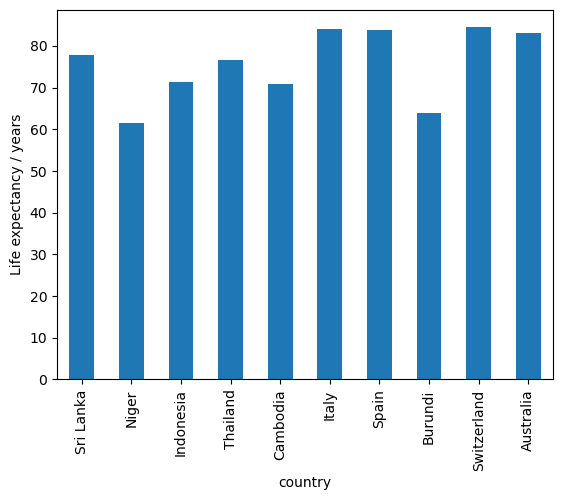

In [125]:
df['life_expectancy'].plot(kind='bar', ylabel='Life expectancy / years')

This sample of data shows similar high life expectancies of the European countries and Australia, followed by countries in Asia, which have a 7-year range. Burundi and Niger are staggeringly low compared to the rest.

# Relationships

## Annual income vs life expectancy

In [155]:
df[['annual_income', 'life_expectancy']].sort_values('annual_income')

,annual_income,life_expectancy
country,,
Burundi,240.0,63.8
Niger,590.0,61.4
Cambodia,1550.0,70.8
Sri Lanka,3820.0,77.7
Indonesia,4140.0,71.3
Thailand,7260.0,76.6
Spain,29740.0,83.9
Italy,35710.0,84.0
Australia,56760.0,83.1


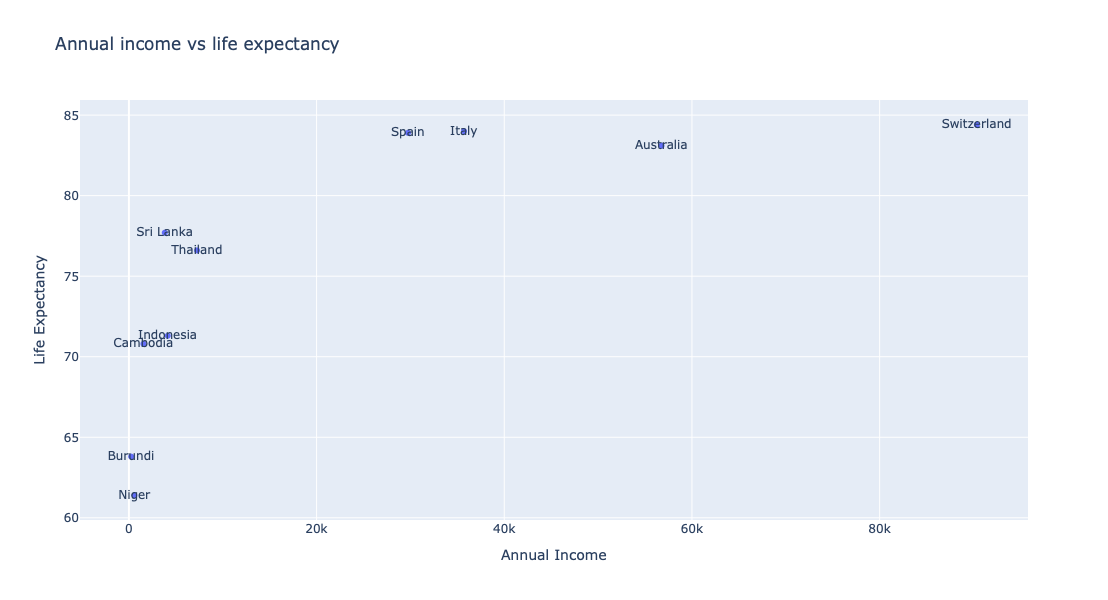

In [147]:
px.scatter(df, x='annual_income', y='life_expectancy', text=df.index,
           title='Annual income vs life expectancy',
          labels={'life_expectancy':'Life Expectancy',
                 'annual_income':'Annual Income'}, height=600)

This data suggests that as annual income increases, life expectancy increases until it plateaus at a point between Spain and Thailand/Sri Lanka. Burundi and Niger are the bottom 2 for both annual income and life expectancy, suggesting a low quality of life within the countries. However, this positive relationship is not a strict rule between countries, as Sri Lanka has a lower annual income than Thailand yet a higher life expectancy. Higher income may allow citizens to access healthcare, nutrition and better living conditions, potentially contributing to longer life expectancies, yet other factors may influence this, and correlation does not prove causation.

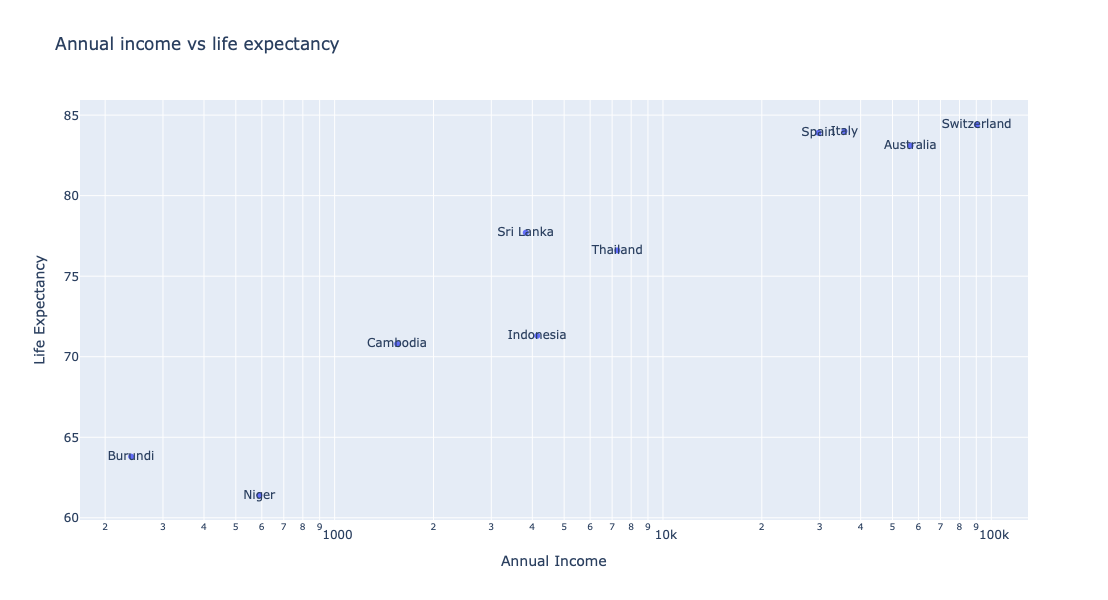

In [163]:
px.scatter(df, x='annual_income', y='life_expectancy', text=df.index,
           title='Annual income vs life expectancy',
          labels={'life_expectancy':'Life Expectancy',
                 'annual_income':'Annual Income'}, log_x=True, height=600)

Using a logarithmic income axis makes the differences between lower-income countries, such as Burundi (240), Niger (590) and Cambodia (1,550), much easier to distinguish visually. This allows income differences to be interpreted proportionally rather than in absolute terms. The graph highlights a positive correlation between annual income and life expectancy, with life expectancy levelling off at higher income levels. This suggests that income increases may be associated with greater improvements in life expectancy among lower-income countries than among wealthier countries, although this pattern cannot be generalised from a sample of only 10 countries.

## Annual income vs enemployment

In [156]:
df[['annual_income', 'unemployment_rate']].sort_values('annual_income')

,annual_income,unemployment_rate
country,,
Burundi,240.0,1.8
Niger,590.0,0.8
Cambodia,1550.0,0.6
Sri Lanka,3820.0,5.4
Indonesia,4140.0,4.4
Thailand,7260.0,1.4
Spain,29740.0,14.7
Italy,35710.0,9.8
Australia,56760.0,5.1


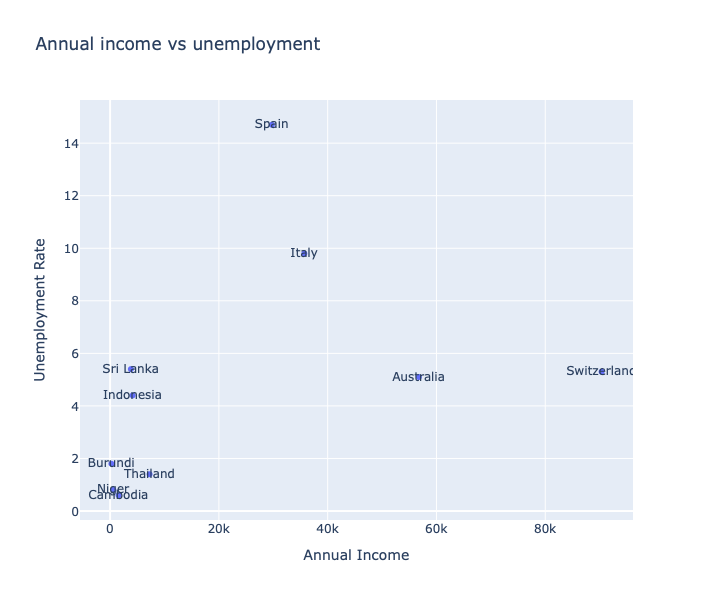

In [146]:
px.scatter(df, x='annual_income', y='unemployment_rate', text=df.index,
           title='Annual income vs unemployment',
          labels={'unemployment_rate':'Unemployment Rate',
                 'annual_income':'Annual Income'}, height=600)

The data shows no strong trend in the relationship between annual income and unemployment. However, there is a weak link between countries having a lower annual income and a lower unemployment rate, disproving the idea that higher employment causes economic growth. Spain has the highest unemployment rate by far, whilst Italy follows, demonstrating no link between a higher income rate past roughly 20k causing a higher unemployment rate.

## Corruption vs life expectancy

In [160]:
df[['corruption_index', 'life_expectancy']].sort_values('corruption_index', ascending=False)

,corruption_index,life_expectancy
country,,
Burundi,81.0,63.8
Cambodia,77.0,70.8
Niger,69.0,61.4
Thailand,65.0,76.6
Sri Lanka,63.0,77.7
Indonesia,62.0,71.3
Italy,44.0,84.0
Spain,39.0,83.9
Australia,27.0,83.1


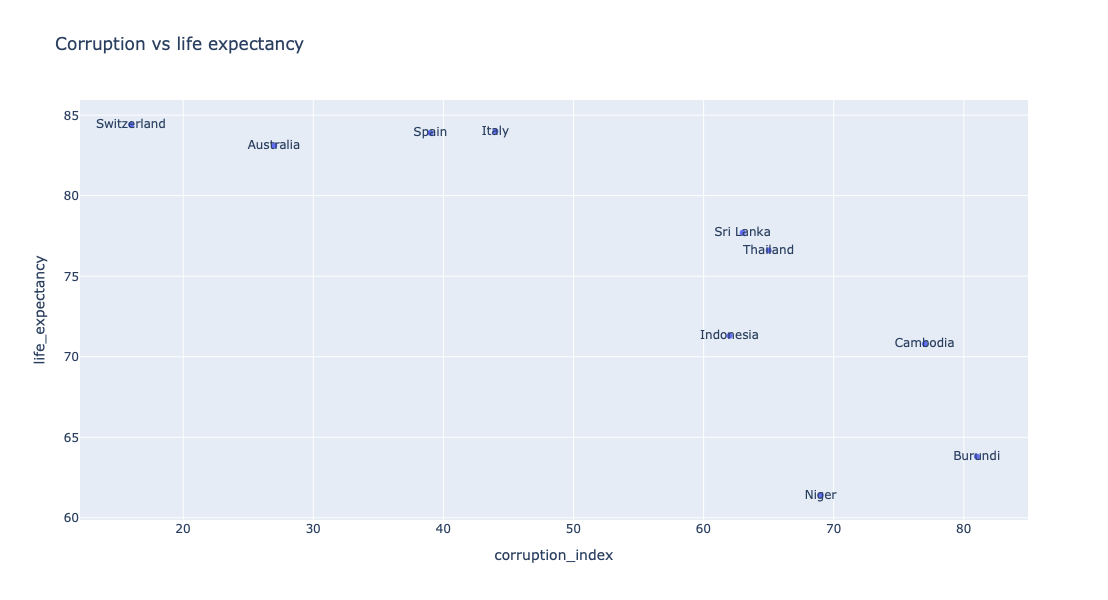

In [150]:
px.scatter(df, x='corruption_index', y='life_expectancy', text=df.index,
           title='Corruption vs life expectancy',
          labels={'unemployment_rate':'Unemployment Rate',
                 'annual_income':'Annual Income'}, height=600)

Corruption appears to increase as life expectancy decreases. Switzerland, Australia, Spain, and Italy have lower corruption indices than the other countries. Still, they show a wide range despite similar life expectancies, suggesting that other factors influence corruption at this point. Niger, Burundi and Cambodia all feature in the bottom three for countries in this sample for life expectancy, while having the three highest levels of corruption, showing a negative correlation between these variables, especially at the lower end of the dataset. This correlation may be due to annual income affecting corruption rather than life expectancy, as life expectancy and annual income are positively correlated.

# Correlation table

In [157]:
df.corr()

,annual_income,corruption_index,unemployment_rate,life_expectancy
annual_income,1.000000,-0.948027,0.387289,0.734314
corruption_index,-0.948027,1.000000,-0.573896,-0.831097
unemployment_rate,0.387289,-0.573896,1.000000,0.707621
life_expectancy,0.734314,-0.831097,0.707621,1.000000


The values represent how strong or weak, and whether negative or positive, the correlations are between variables. The strongest correlation is a negative one between annual income and corruption index (-0.95). This may be due to low income causing powerful people within countries to desire to misuse their power, or people may be using their power correctly, causing economic growth and thus increased annual income. Annual income and unemployment rate have the weakest correlation (0.39); overall, employment rate has the weakest correlation with other variables (0.39, -0.57, 0.71), implying that it may not highly affect the prosperity of a country.

In [173]:
df.drop(index=['Spain', 'Italy'])[['annual_income', 'unemployment_rate']].corr()

,annual_income,unemployment_rate
annual_income,1.000000,0.607369
unemployment_rate,0.607369,1.000000


After removing Spain and Italy, the correlation between annual income and unemployment rate increases by 0.22, suggesting these two countries heavily influence the relationship.

# Conclusion

Overall, the data suggests that a higher annual income is associated with higher life expectancy and lower corruption. The strongest correlation was between annual index and corruption index (-0.95), while unemployment had the weakest relationship with other variables. However, exceptions between variables show that economic development is influenced by multiple factors, not income alone. As analysis used only 10 countries, the results may not represent global trends and correlation does not prove causation.